<table style="border:none;width:100%"><tr>
<td style="border:none;text-align:left;vertical-align:middle">
<h1 style="color:#54A021;margin-bottom:0">LAB — Modulação e Demodulação 8-PSK</h1>
<p style="color:#2C3C43;font-size:15px;margin-top:4px">
<b>SCM203405 — Sistemas de Comunicação</b><br>
Superior em Eletrônica Industrial — IFSC Florianópolis</p>
</td>


## Apresentação

Neste laboratório você vai acompanhar, **bloco a bloco**, a cadeia completa de um sistema 8-PSK:
bits → conversor S/P → *look-up table* (sinais I e Q) → portadoras → sinal modulado $s(t)$ →
canal com ruído AWGN → correlatores → $\arctan(Y/X)$ → decisão pela fase → bits recebidos.

Todo o código já está implementado. O seu trabalho **não é programar do zero**, e sim
**interpretar cada sinal**, prever resultados antes de executar, conferir a teoria contra a simulação
e explicar o que acontece quando os parâmetros mudam. Você pode (e deve) usar IA como apoio — da mesma
forma que usaria um livro ou um colega —, mas as perguntas foram construídas para que a resposta dependa
**dos seus próprios gráficos e parâmetros**, que são diferentes dos de cada colega.

**Como trabalhar:** execute as células em ordem (`Shift+Enter`). As células marcadas com
`# <-- ALTERE` são as únicas que você precisa editar. Responda nas células **✍️ Resposta**.

| Parte | Conteúdo |
|---|---|
| 0 | Parâmetros individuais (a partir da sua matrícula) |
| 1 | Modulador 8-PSK: bits, S/P, *look-up table*, I/Q, portadoras, $s(t)$ no tempo e na frequência |
| 2 | Canal AWGN — você escolhe o $E_b/N_0$ |
| 3 | Demodulador: correlatores, $\arctan(Y/X)$, decisão pela fase, mapeamento reverso |
| 4 | Constelação com ruído e curva de BER (simulada × teórica) |
| 5 | Auditoria: encontre os erros no decisor de um "colega" |
| 6 | E se…? Análise de sensibilidade |
| 7 | Entregáveis e rubrica de avaliação |

In [ ]:
# ============ Bibliotecas e estilo dos gráficos (execute sem alterar) ============
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.special import erfc
from scipy.signal import welch

# Paleta IFSC
VERDE, VERDE_ESC, CINZA = '#90C226', '#54A021', '#2C3C43'
AMARELO, LARANJA, VERMELHO, AZUL = '#E6B91E', '#E76618', '#C42F1A', '#1F77B4'

plt.rcParams.update({
    'figure.figsize': (11, 3.6), 'figure.dpi': 100,
    'axes.grid': True, 'grid.alpha': 0.3,
    'axes.titleweight': 'bold', 'axes.titlecolor': VERDE_ESC,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10,
})
pd.set_option('display.precision', 4)
print('Ambiente pronto.')

---
## Parte 0 — Parâmetros individuais

A sua **matrícula** gera uma semente aleatória que define: a sequência de 12 bits transmitida,
a frequência da portadora e dois valores de referência usados nas análises (Eb/N0 e erro de fase).
Assim, cada aluno tem sinais, tabelas e gráficos próprios.

⚠️ **Digite sua matrícula antes de qualquer outra coisa** e não altere depois: as respostas serão
conferidas com os parâmetros gerados por ela.

In [ ]:
MATRICULA = "202209892"   # <-- ALTERE: digite sua matrícula (somente números)

# ------------------------------------------------------------------------------
digitos = ''.join(c for c in MATRICULA if c.isdigit())
assert len(digitos) > 0, 'Digite uma matrícula válida.'
if set(digitos) == {'0'}:
    print('⚠️  ATENÇÃO: você ainda está usando a matrícula padrão! Altere a variável MATRICULA.\n')
SEED = int(digitos) % (2**32)
rng_aluno = np.random.default_rng(SEED)

# ---------------- Parâmetros do sistema ----------------
M      = 8                    # número de símbolos (8-PSK)
k      = int(np.log2(M))      # bits por símbolo
N_BITS = 12                   # bits transmitidos (-> 4 símbolos)

Ts  = 1e-3                    # duração do símbolo [s]  -> Rs = 1 kbaud
Rs  = 1/Ts
Tb  = Ts/k                    # duração do bit [s]
Rb  = 1/Tb                    # taxa de bits [bit/s]

N_CICLOS = int(rng_aluno.choice([2, 3, 4, 5]))   # ciclos de portadora por símbolo
fc  = N_CICLOS/Ts                                  # frequência da portadora [Hz]

SPS = 240                     # amostras por símbolo (divisível por k=3)
fs  = SPS/Ts                  # frequência de amostragem da simulação [Hz]
dt  = 1/fs

A   = 1.0                     # amplitude de pico de s(t) [V]
E   = A**2*Ts/2               # energia por símbolo [J] (resistor de 1 ohm)  -> A = sqrt(2E/Ts)

bits_tx = rng_aluno.integers(0, 2, N_BITS)
EbN0_REF_dB   = int(rng_aluno.choice([3, 5, 7, 9]))      # Eb/N0 de referência (Partes 2 e 6)
OFFSET_REF_deg = int(rng_aluno.choice([10, 15, 20, 30])) # erro de fase de referência (Parte 6)

print(f'Matrícula ................ {MATRICULA}  (semente {SEED})')
print(f'Bits transmitidos ........ {"".join(map(str, bits_tx))}')
print(f'Rb = {Rb:.0f} bit/s   Tb = {Tb*1e3:.4f} ms')
print(f'Rs = {Rs:.0f} baud    Ts = {Ts*1e3:.1f} ms')
print(f'fc = {fc/1e3:.0f} kHz  ({N_CICLOS} ciclos por símbolo)')
print(f'E  = {E:.3e} J   (sqrt(E) = {np.sqrt(E):.4e})')
print(f'Eb/N0 de referência ...... {EbN0_REF_dB} dB')
print(f'Erro de fase de referência {OFFSET_REF_deg}°')

---
## Parte 1 — Modulador 8-PSK

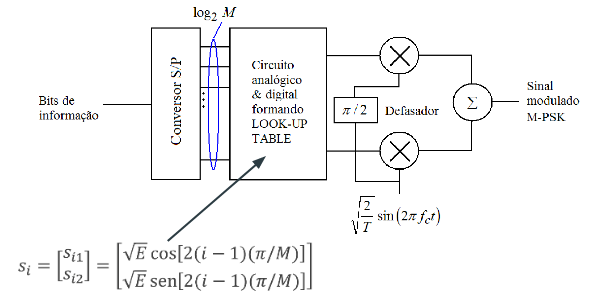

O conversor S/P agrupa os bits de $\log_2 M = 3$ em 3. Cada grupo endereça a *look-up table*, que
entrega os coeficientes $s_{i1}$ (ramo em fase, I) e $s_{i2}$ (ramo em quadratura, Q). Esses coeficientes
multiplicam as funções-base (portadoras) e são somados:

**Forma geral do sinal M-PSK (símbolo $i$, $0 \le t \le T_s$):**

$$s_i(t) = s_{i1}\,\psi_1(t) + s_{i2}\,\psi_2(t),\qquad
\psi_1(t)=\sqrt{\tfrac{2}{T_s}}\cos(2\pi f_c t),\quad
\psi_2(t)=\sqrt{\tfrac{2}{T_s}}\sin(2\pi f_c t)$$

**Coeficientes da *look-up table* (equação geral do roteiro):**

$$\mathbf{s}_i=\begin{bmatrix}s_{i1}\\ s_{i2}\end{bmatrix}=
\begin{bmatrix}\sqrt{E}\cos[2(i-1)\pi/M]\\ \sqrt{E}\sin[2(i-1)\pi/M]\end{bmatrix},\qquad i=1,\dots,M$$

**Forma equivalente (amplitude e fase):** substituindo e usando $\cos a\cos b+\sin a\sin b=\cos(a-b)$,

$$s_i(t)=\sqrt{\tfrac{2E}{T_s}}\cos\!\left(2\pi f_c t-\phi_i\right),\qquad \phi_i = \frac{2(i-1)\pi}{M}$$

**Interpretação:** todos os símbolos têm a **mesma amplitude** (mesma energia $E$); a informação está
**somente na fase** $\phi_i$, que salta de 45° em 45° no 8-PSK.

### 1.1 — Sequência de bits no tempo e na frequência

O primeiro gráfico mostra seus 12 bits em formato NRZ unipolar. O segundo mostra o espectro dessa
sequência curta, e o terceiro a densidade espectral de potência (DEP) de uma sequência **longa** e
aleatória com a mesma taxa $R_b$, onde o formato típico $\text{sinc}^2$ fica bem visível.

In [ ]:
t_bits = np.arange(N_BITS*SPS//k)*dt
x_bits = np.repeat(bits_tx, SPS//k).astype(float)

def espectro(x, fs, nfft=2**16):
    """Módulo da transformada de Fourier (aproximação da TF contínua)."""
    X = np.fft.fftshift(np.fft.fft(x, nfft))/fs
    f = np.fft.fftshift(np.fft.fftfreq(nfft, 1/fs))
    return f, np.abs(X)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(t_bits*1e3, x_bits, color=VERDE_ESC, lw=2)
for n, b in enumerate(bits_tx):
    ax[0].text((n+0.5)*Tb*1e3, 1.12, str(b), ha='center', color=CINZA, fontweight='bold')
for n in range(N_BITS+1):
    ax[0].axvline(n*Tb*1e3, color='gray', ls=':', lw=0.7)
ax[0].set(title='Bits no tempo (NRZ unipolar)', xlabel='t [ms]', ylabel='amplitude', ylim=(-0.2, 1.3))

f, Xb = espectro(x_bits, fs)
ax[1].plot(f/1e3, Xb, color=VERDE_ESC)
ax[1].set(title='|X(f)| — seus 12 bits', xlabel='f [kHz]', xlim=(-4*Rb/1e3, 4*Rb/1e3))
for m in range(1, 4):
    ax[1].axvline( m*Rb/1e3, color=LARANJA, ls='--', lw=0.8)
    ax[1].axvline(-m*Rb/1e3, color=LARANJA, ls='--', lw=0.8)

rng_longa = np.random.default_rng(SEED + 99)
x_longa = np.repeat(rng_longa.integers(0, 2, 4000), SPS//k).astype(float)
fw, Pw = welch(x_longa - x_longa.mean(), fs=fs, nperseg=4096, return_onesided=False)
fw, Pw = np.fft.fftshift(fw), np.fft.fftshift(Pw)
ax[2].semilogy(fw/1e3, Pw, color=AZUL)
for m in range(1, 4):
    ax[2].axvline( m*Rb/1e3, color=LARANJA, ls='--', lw=0.8)
    ax[2].axvline(-m*Rb/1e3, color=LARANJA, ls='--', lw=0.8)
ax[2].set(title='DEP — sequência longa (sem a componente DC)', xlabel='f [kHz]',
          xlim=(-4*Rb/1e3, 4*Rb/1e3), ylim=(Pw.max()*1e-4, Pw.max()*3))
plt.tight_layout(); plt.show()
print(f'Linhas tracejadas laranja: múltiplos de Rb = {Rb:.0f} Hz')

**Questões 1.1**

a) Onde ficam os nulos do espectro da sequência longa? Relacione com $T_b$ usando **os seus valores numéricos**.<br>
b) O NRZ unipolar tem uma componente DC (um impulso em $f=0$, removido no gráfico da direita). De onde ela vem?

> ✍️ **Resposta:** _Escreva aqui sua resposta._

### 1.2 — Conversor S/P e *look-up table* com código Gray

O mapeamento segue o código Gray do roteiro, percorrendo a constelação no sentido anti-horário a partir de 0°:
$S_1\to111,\ S_2\to110,\ S_3\to010,\ S_4\to011,\ S_5\to001,\ S_6\to000,\ S_7\to100,\ S_8\to101$.

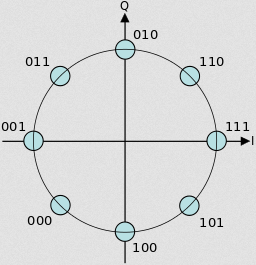

✏️ **Antes de executar a próxima célula:** calcule **à mão** $s_{i1}/\sqrt{E}$ e $s_{i2}/\sqrt{E}$ para
$S_2$ e $S_6$ e anote na resposta da Questão 1.2. Depois compare com a tabela gerada.

In [ ]:
# ---------------- Look-up table a partir da equação geral ----------------
idx_i   = np.arange(1, M+1)                     # i = 1..M
phi_i   = 2*(idx_i - 1)*np.pi/M                 # fases [rad]
s_i1    = np.sqrt(E)*np.cos(phi_i)              # coeficiente em fase (I)
s_i2    = np.sqrt(E)*np.sin(phi_i)              # coeficiente em quadratura (Q)
GRAY    = ['111', '110', '010', '011', '001', '000', '100', '101']   # S1..S8
BITS2IDX = {g: n for n, g in enumerate(GRAY)}

lut = pd.DataFrame({
    'Símbolo': [f'S{i}' for i in idx_i],
    'Bits (Gray)': GRAY,
    'φ_i [°]': np.degrees(phi_i).round(1),
    's_i1/√E': (s_i1/np.sqrt(E)).round(4),
    's_i2/√E': (s_i2/np.sqrt(E)).round(4),
    's_i1': s_i1, 's_i2': s_i2,
})
display(lut)

# Verificação da propriedade Gray: vizinhos diferem em 1 bit
dif = [sum(a != b for a, b in zip(GRAY[n], GRAY[(n+1) % M])) for n in range(M)]
print('Bits diferentes entre símbolos vizinhos:', dif)

# ---------------- Conversor S/P ----------------
grupos    = bits_tx.reshape(-1, k)
idx_tx    = np.array([BITS2IDX[''.join(map(str, g))] for g in grupos])
N_SIM     = len(idx_tx)
display(pd.DataFrame({
    'Intervalo': [f'{n*Ts*1e3:.0f}–{(n+1)*Ts*1e3:.0f} ms' for n in range(N_SIM)],
    'Grupo de bits': [''.join(map(str, g)) for g in grupos],
    'Símbolo': [f'S{n+1}' for n in idx_tx],
    'φ_i [°]': np.degrees(phi_i[idx_tx]).round(1),
    'I = s_i1/√E': (s_i1[idx_tx]/np.sqrt(E)).round(4),
    'Q = s_i2/√E': (s_i2[idx_tx]/np.sqrt(E)).round(4),
}))

# ---------------- Constelação ideal ----------------
fig, ax = plt.subplots(figsize=(5, 5))
circ = np.linspace(0, 2*np.pi, 300)
ax.plot(np.cos(circ), np.sin(circ), color='gray', lw=0.7)
ax.scatter(s_i1/np.sqrt(E), s_i2/np.sqrt(E), s=160, color=VERDE, edgecolor=VERDE_ESC, zorder=3)
ax.scatter(s_i1[idx_tx]/np.sqrt(E), s_i2[idx_tx]/np.sqrt(E), s=320, facecolor='none',
           edgecolor=VERMELHO, lw=2, zorder=4, label='usados na sua sequência')
for n in range(M):
    ax.annotate(f'S{n+1}\n{GRAY[n]}', (1.28*np.cos(phi_i[n]), 1.28*np.sin(phi_i[n])),
                ha='center', va='center', fontsize=9)
ax.axhline(0, color=CINZA, lw=0.8); ax.axvline(0, color=CINZA, lw=0.8)
ax.set(xlim=(-1.6, 1.6), ylim=(-1.6, 1.6), aspect='equal', xlabel='I  (s_i1/√E)', ylabel='Q  (s_i2/√E)',
       title='Constelação 8-PSK (Gray)')
ax.legend(loc='lower right', fontsize=8); plt.show()

**Questões 1.2**

a) Registre seus cálculos manuais para $S_2$ e $S_6$ e compare com a tabela.<br>
b) Qual a vantagem do código Gray quando o ruído faz o receptor confundir um símbolo com o **vizinho**? <br>
c) Calcule a distância euclidiana entre dois símbolos vizinhos em função de $\sqrt{E}$ ($d = 2\sqrt{E}\sin(\pi/M)$).

> ✍️ **Resposta:** _Escreva aqui sua resposta._

### 1.3 — Sinais I e Q (saída da *look-up table*)

Os coeficientes $s_{i1}$ e $s_{i2}$ ficam constantes durante cada intervalo de símbolo $T_s$.

In [ ]:
t = np.arange(N_SIM*SPS)*dt
I_t = np.repeat(s_i1[idx_tx], SPS)
Q_t = np.repeat(s_i2[idx_tx], SPS)

def marca_simbolos(ax, n_sim, rotulos=True, y=None):
    for n in range(n_sim+1):
        ax.axvline(n*Ts*1e3, color='gray', ls=':', lw=0.8)
    if rotulos:
        yl = ax.get_ylim()[1] if y is None else y
        for n in range(n_sim):
            ax.text((n+0.5)*Ts*1e3, yl, f'S{idx_tx[n]+1} ({GRAY[idx_tx[n]]})',
                    ha='center', va='bottom', fontsize=8, color=CINZA)

fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ax[0].plot(t*1e3, I_t/np.sqrt(E), color=VERDE_ESC, lw=2); ax[0].set(ylabel='I(t)/√E', ylim=(-1.3, 1.3))
ax[1].plot(t*1e3, Q_t/np.sqrt(E), color=LARANJA,  lw=2); ax[1].set(ylabel='Q(t)/√E', ylim=(-1.3, 1.3), xlabel='t [ms]')
marca_simbolos(ax[0], N_SIM); marca_simbolos(ax[1], N_SIM, rotulos=False)
ax[0].set_title('Sinais I e Q na saída da look-up table', pad=18)
plt.tight_layout(); plt.show()

### 1.4 — Portadoras (funções-base) e sinal modulado $s(t)$

In [ ]:
psi1 = np.sqrt(2/Ts)*np.cos(2*np.pi*fc*t)      # função-base 1 (ramo I)
psi2 = np.sqrt(2/Ts)*np.sin(2*np.pi*fc*t)      # função-base 2 (ramo Q) = psi1 defasada de pi/2

ramo_I = I_t*psi1
ramo_Q = Q_t*psi2
s_t    = ramo_I + ramo_Q                        # sinal 8-PSK transmitido

# Verificação numérica da ortonormalidade em um intervalo de símbolo
seg = slice(0, SPS)
print(f'∫ψ1² dt = {np.sum(psi1[seg]**2)*dt:.4f}   ∫ψ2² dt = {np.sum(psi2[seg]**2)*dt:.4f}   '
      f'∫ψ1·ψ2 dt = {np.sum(psi1[seg]*psi2[seg])*dt:.2e}')

fig, ax = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
ax[0].plot(t*1e3, psi1, color=VERDE_ESC, label='ψ1(t) = √(2/Ts) cos(2πfc t)')
ax[0].plot(t*1e3, psi2, color=LARANJA, ls='--', label='ψ2(t) = √(2/Ts) sin(2πfc t)')
ax[0].legend(loc='upper right', fontsize=8); ax[0].set_title('Portadoras (funções-base)')
ax[1].plot(t*1e3, ramo_I, color=VERDE_ESC); ax[1].set_title('Ramo I:  s_i1 · ψ1(t)')
ax[2].plot(t*1e3, ramo_Q, color=LARANJA);   ax[2].set_title('Ramo Q:  s_i2 · ψ2(t)')
ax[3].plot(t*1e3, s_t, color=CINZA);        ax[3].set_title('Sinal modulado s(t) = ramo I + ramo Q', pad=18)
ax[3].set_xlabel('t [ms]')
for a in ax: marca_simbolos(a, N_SIM, rotulos=False)
marca_simbolos(ax[3], N_SIM)
plt.tight_layout(); plt.show()

In [ ]:
# Espectro de s(t): seus 4 símbolos × sequência longa aleatória
def modulador_8psk(idx, sps, fc_, Ts):
    dt_ = Ts/sps
    tt = np.arange(len(idx)*sps)*dt_
    return (np.repeat(s_i1[idx], sps)*np.sqrt(2/Ts)*np.cos(2*np.pi*fc_*tt) +
            np.repeat(s_i2[idx], sps)*np.sqrt(2/Ts)*np.sin(2*np.pi*fc_*tt))

f, S = espectro(s_t, fs)
idx_longo = np.random.default_rng(SEED + 98).integers(0, M, 3000)
s_longo = modulador_8psk(idx_longo, SPS, fc, Ts)
fw, Pw = welch(s_longo, fs=fs, nperseg=8192)
PdB = 10*np.log10(Pw/Pw.max() + 1e-15)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(f/1e3, S, color=CINZA)
ax[0].set(title='|S(f)| — seus 4 símbolos', xlabel='f [kHz]', xlim=(-2*fc/1e3-3, 2*fc/1e3+3))
ax[1].plot(fw/1e3, PdB, color=AZUL)
for m in [-3, -2, -1, 1, 2, 3]:
    ax[1].axvline((fc + m*Rs)/1e3, color=LARANJA, ls='--', lw=0.8)
ax[1].axvline(fc/1e3, color=VERDE_ESC, lw=1.5)
ax[1].set(title='DEP 8-PSK — sequência longa aleatória [dB]', xlabel='f [kHz]',
          xlim=((fc-5*Rs)/1e3, (fc+5*Rs)/1e3), ylim=(-45, 3))
plt.tight_layout(); plt.show()
print(f'Verde: fc = {fc/1e3:.0f} kHz | Laranja: fc ± m·Rs (Rs = {Rs:.0f} baud)')

**Questões 1.3 / 1.4**

a) Nos gráficos das portadoras e de $s(t)$, identifique os instantes em que há **salto de fase**. Para cada fronteira entre símbolos da **sua** sequência, qual é o salto de fase esperado (em graus)? Ele é visível no gráfico?<br>
b) A amplitude de $s(t)$ muda de um símbolo para outro? Justifique com a forma $\sqrt{2E/T_s}\cos(2\pi f_c t - \phi_i)$.<br>
c) Na DEP da sequência longa, onde está centrado o lóbulo principal e qual a largura entre os primeiros nulos? <br>
d) A verificação numérica $\int\psi_1\psi_2\,dt\approx 0$ só funciona bem porque $f_c$ é múltiplo inteiro de $R_s$ no seu caso. Por que essa condição importa?

> ✍️ **Resposta:** _Escreva aqui sua resposta._

---
## Parte 2 — Canal com ruído AWGN

O canal soma ao sinal um ruído branco gaussiano $n(t)$ com densidade espectral bilateral $N_0/2$:
$r(t) = s(t) + n(t)$.

A relação entre energia por bit e energia por símbolo no 8-PSK é $E_b = E/\log_2 M = E/3$. Dado o
$E_b/N_0$ (em dB) que **você** escolher, o simulador calcula $N_0$ e gera amostras de ruído com variância
$\sigma^2 = N_0/(2\,\Delta t)$ — isso garante que, **na saída de cada correlator**, o ruído tenha variância
exatamente $N_0/2$, como prevê a teoria.

👉 Comece com o seu $E_b/N_0$ de referência (Parte 0). Depois volte aqui e teste outros valores
(por exemplo 20 dB, 10 dB, 3 dB e 0 dB), reexecutando as Partes 2 e 3.

In [ ]:
EbN0_dB = EbN0_REF_dB     # <-- ALTERE: informe o Eb/N0 desejado em dB (ex.: 20, 10, 5, 0)

def canal_awgn(s, EbN0_dB, E, k, dt, rng):
    Eb    = E/k
    N0    = Eb/10**(EbN0_dB/10)
    sigma = np.sqrt(N0/(2*dt))
    return s + sigma*rng.standard_normal(len(s)), N0

rng_canal = np.random.default_rng(SEED + 1)
r_t, N0 = canal_awgn(s_t, EbN0_dB, E, k, dt, rng_canal)
print(f'Eb/N0 = {EbN0_dB} dB  ->  Eb = {E/k:.3e} J,  N0 = {N0:.3e} W/Hz,  Es/N0 = {10*np.log10(E/N0):.2f} dB')
print(f'Desvio-padrão esperado do ruído na saída do correlator (normalizado por √E): '
      f'{np.sqrt(N0/2)/np.sqrt(E):.4f}')

fig, ax = plt.subplots(2, 1, figsize=(11, 6))
ax[0].plot(t*1e3, r_t, color=VERMELHO, lw=0.6, alpha=0.8, label='r(t) = s(t) + n(t)')
ax[0].plot(t*1e3, s_t, color=CINZA, lw=1.4, label='s(t)')
marca_simbolos(ax[0], N_SIM); ax[0].legend(loc='upper right', fontsize=8)
ax[0].set(title=f'Sinal recebido — Eb/N0 = {EbN0_dB} dB', xlabel='t [ms]')
fr, R = espectro(r_t, fs)
ax[1].plot(fr/1e3, 20*np.log10(R/S.max()+1e-12), color=VERMELHO, lw=0.6, label='|R(f)|')
ax[1].plot(f/1e3,  20*np.log10(S/S.max()+1e-12), color=CINZA, lw=1.2, label='|S(f)|')
ax[1].set(title='Espectro (dB, normalizado ao pico de |S(f)|)', xlabel='f [kHz]',
          xlim=(0, 3*fc/1e3), ylim=(-60, 5))
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Questões 2**

a) Com $E_b/N_0 = 20$ dB e $E_b/N_0 = 0$ dB, compare visualmente $r(t)$ com $s(t)$. Ainda é possível "ver" o salto de fase a olho?<br>
b) No espectro, o ruído aparece como um patamar aproximadamente plano. Por que ele é plano? O que aconteceria com a altura desse patamar se o $E_b/N_0$ diminuísse 10 dB?

> ✍️ **Resposta:** _Escreva aqui sua resposta._

---
## Parte 3 — Demodulador por correlação

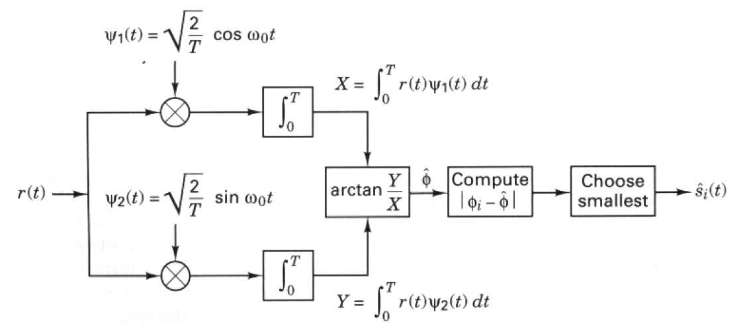

**Saídas dos correlatores (forma geral):**

$$X = \int_0^{T_s} r(t)\,\psi_1(t)\,dt \quad\text{(ramo em fase)},\qquad
Y = \int_0^{T_s} r(t)\,\psi_2(t)\,dt \quad\text{(ramo em quadratura)}$$

**Caso particular — sem ruído, portadoras sincronizadas e $f_c$ múltiplo de $R_s$:** pela ortonormalidade
de $\psi_1,\psi_2$, $X = s_{i1} = \sqrt{E}\cos\phi_i$ e $Y = s_{i2} = \sqrt{E}\sin\phi_i$.

**Com ruído AWGN:** $X = \sqrt{E}\cos\phi_i + n_X$, $Y = \sqrt{E}\sin\phi_i + n_Y$, com
$n_X, n_Y \sim \mathcal{N}(0, N_0/2)$ independentes.

**Estimativa de fase e decisão:**

$$\hat\phi = \arctan\frac{Y}{X} \;(\text{calculado com }\texttt{arctan2}),\qquad
\hat{\imath} = \arg\min_i\;\big|\phi_i - \hat\phi\big|$$

**Interpretação:** o par $(X, Y)$ é a **projeção** do sinal recebido no plano da constelação; o ruído
desloca o ponto em torno do símbolo ideal, e o decisor escolhe o símbolo cuja fase está mais próxima.

> Observação: $\psi_1$ (cosseno) gera a saída **em fase** $X$ e $\psi_2$ (seno) gera a saída **em quadratura** $Y$,
exatamente como no diagrama.

O receptor abaixo tem um parâmetro de **erro de fase da portadora local** (`OFFSET_deg`), que simula um
sincronismo imperfeito. Mantenha em **0** por enquanto; ele será usado na Parte 6.

In [ ]:
OFFSET_deg = 0      # <-- ALTERE somente na Parte 6 (erro de fase da portadora do receptor, em graus)

def correlator(r, fc, Ts, sps, dt, offset_deg=0.0):
    """Multiplica r(t) pelas funções-base locais e integra a cada Ts (integra-e-descarrega)."""
    tt = np.arange(len(r))*dt
    th = np.deg2rad(offset_deg)
    p1 = np.sqrt(2/Ts)*np.cos(2*np.pi*fc*tt + th)
    p2 = np.sqrt(2/Ts)*np.sin(2*np.pi*fc*tt + th)
    prod1, prod2 = r*p1, r*p2
    integ1 = np.cumsum(prod1.reshape(-1, sps), axis=1)*dt   # integral acumulada dentro de cada símbolo
    integ2 = np.cumsum(prod2.reshape(-1, sps), axis=1)*dt
    return dict(prod1=prod1, prod2=prod2, integ1=integ1.ravel(), integ2=integ2.ravel(),
                X=integ1[:, -1], Y=integ2[:, -1])

rx = correlator(r_t, fc, Ts, SPS, dt, OFFSET_deg)
X, Y = rx['X'], rx['Y']

fig, ax = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
ax[0, 0].plot(t*1e3, rx['prod1'], color=VERDE_ESC, lw=0.7); ax[0, 0].set_title('r(t)·ψ1(t)  (antes do integrador)')
ax[1, 0].plot(t*1e3, rx['prod2'], color=LARANJA,  lw=0.7);  ax[1, 0].set_title('r(t)·ψ2(t)  (antes do integrador)')
ax[0, 1].plot(t*1e3, rx['integ1']/np.sqrt(E), color=VERDE_ESC, lw=1.5)
ax[1, 1].plot(t*1e3, rx['integ2']/np.sqrt(E), color=LARANJA, lw=1.5)
t_amostra = (np.arange(N_SIM)+1)*Ts - dt
ax[0, 1].scatter(t_amostra*1e3, X/np.sqrt(E), color=VERMELHO, zorder=4, label='X amostrado em Ts')
ax[1, 1].scatter(t_amostra*1e3, Y/np.sqrt(E), color=VERMELHO, zorder=4, label='Y amostrado em Ts')
ax[0, 1].set_title('Saída do correlator em fase  X/√E'); ax[1, 1].set_title('Saída do correlator em quadratura  Y/√E')
for a in ax.ravel(): marca_simbolos(a, N_SIM, rotulos=False)
for a in ax[:, 1]: a.legend(fontsize=8, loc='lower left'); a.set_ylim(-1.4, 1.4)
for a in ax[1]: a.set_xlabel('t [ms]')
plt.tight_layout(); plt.show()

**Questões 3.1**

a) Descreva a forma de onda na saída do integrador dentro de um intervalo de símbolo. Por que ela é uma "rampa" (aproximadamente) e por que é zerada no início de cada símbolo?<br>
b) Por que a decisão usa **apenas o valor no fim do intervalo** ($t = T_s$) e não a forma de onda inteira?<br>
c) Compare os valores de $X/\sqrt{E}$ e $Y/\sqrt{E}$ com a coluna I/Q da tabela da Parte 1.2. A diferença é compatível com o desvio-padrão do ruído impresso na Parte 2?

> ✍️ **Resposta:** _Escreva aqui sua resposta._

In [ ]:
# ---------------- arctan(Y/X) e decisão pela menor diferença de fase ----------------
def decisor_fase(X, Y, phi_i):
    phi_hat = np.arctan2(Y, X)                               # fase estimada em (-π, π]
    dphi = np.angle(np.exp(1j*(phi_i[None, :] - phi_hat[:, None])))   # diferença "enrolada" em (-π, π]
    dist = np.abs(dphi)
    return phi_hat, dist, np.argmin(dist, axis=1)

def demapeia(idx):
    return np.array([int(b) for n in idx for b in GRAY[n]])

phi_hat, dist, idx_rx = decisor_fase(X, Y, phi_i)
bits_rx = demapeia(idx_rx)

tab = pd.DataFrame({
    'X/√E (fase)': X/np.sqrt(E), 'Y/√E (quadr.)': Y/np.sqrt(E),
    'φ̂ [°]': np.degrees(phi_hat),
    'φ̂ em [0,360) [°]': np.mod(np.degrees(phi_hat), 360),
    'Transmitido': [f'S{n+1}' for n in idx_tx],
    'Decidido': [f'S{n+1}' for n in idx_rx],
    'Bits rx': [GRAY[n] for n in idx_rx],
})
display(tab)

print('|φ_i − φ̂| em graus (linha = símbolo recebido, coluna = candidato S1..S8):')
dist_df = pd.DataFrame(np.degrees(dist).round(1), columns=[f'S{i}' for i in idx_i],
                       index=[f'símb. {n+1}' for n in range(N_SIM)])
display(dist_df.style.highlight_min(axis=1, color='#C8E6A0'))

In [ ]:
# ---------------- Constelação recebida e comparação de bits ----------------
fig = plt.figure(figsize=(13, 4.8))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(np.cos(circ), np.sin(circ), color='gray', lw=0.7)
for b in np.arange(M)*2*np.pi/M + np.pi/M:                  # fronteiras de decisão
    ax1.plot([0, 1.7*np.cos(b)], [0, 1.7*np.sin(b)], color=AMARELO, ls='--', lw=1)
ax1.scatter(s_i1/np.sqrt(E), s_i2/np.sqrt(E), s=120, color=VERDE, edgecolor=VERDE_ESC, zorder=3, label='ideal')
for n in range(M):
    ax1.annotate(GRAY[n], (1.35*np.cos(phi_i[n]), 1.35*np.sin(phi_i[n])), ha='center', va='center', fontsize=8)
for n in range(N_SIM):
    ok = idx_rx[n] == idx_tx[n]
    ax1.annotate('', xy=(X[n]/np.sqrt(E), Y[n]/np.sqrt(E)),
                 xytext=(s_i1[idx_tx[n]]/np.sqrt(E), s_i2[idx_tx[n]]/np.sqrt(E)),
                 arrowprops=dict(arrowstyle='->', color=CINZA, lw=1))
    ax1.scatter(X[n]/np.sqrt(E), Y[n]/np.sqrt(E), s=70, marker='X',
                color=AZUL if ok else VERMELHO, zorder=5)
    ax1.annotate(f' {n+1}', (X[n]/np.sqrt(E), Y[n]/np.sqrt(E)), fontsize=9, color=CINZA)
ax1.set(xlim=(-1.8, 1.8), ylim=(-1.8, 1.8), aspect='equal', xlabel='X/√E', ylabel='Y/√E',
        title=f'Deslocamento dos símbolos — Eb/N0 = {EbN0_dB} dB, offset = {OFFSET_deg}°')

ax2 = fig.add_subplot(1, 2, 2)
nb = np.arange(N_BITS)
ax2.step(np.append(nb, N_BITS), np.append(bits_tx, bits_tx[-1]) + 1.5, where='post', color=VERDE_ESC, lw=2, label='transmitidos')
ax2.step(np.append(nb, N_BITS), np.append(bits_rx, bits_rx[-1]),      where='post', color=AZUL, lw=2, label='demodulados')
for e in np.where(bits_tx != bits_rx)[0]:
    ax2.axvspan(e, e+1, color=VERMELHO, alpha=0.25)
for n in range(N_SIM+1): ax2.axvline(n*k, color='gray', ls=':', lw=0.8)
ax2.set(yticks=[0, 1, 1.5, 2.5], yticklabels=['0', '1', '0', '1'], xlabel='índice do bit',
        title='Bits transmitidos (acima) × demodulados (abaixo)')
ax2.legend(loc='center right', fontsize=8)
plt.tight_layout(); plt.show()

n_err = int(np.sum(bits_tx != bits_rx))
print('Transmitidos:', ''.join(map(str, bits_tx)))
print('Demodulados :', ''.join(map(str, bits_rx)))
print(f'Erros de bit: {n_err}/{N_BITS}    Erros de símbolo: {int(np.sum(idx_tx != idx_rx))}/{N_SIM}')

**Questões 3.2**

a) Na tabela de $|\phi_i-\hat\phi|$, localize o valor mínimo de cada linha e explique como ele define o símbolo decidido. Qual foi a **margem** (diferença entre o menor e o segundo menor valor) de cada um dos seus símbolos? <br>
b) Diminua o $E_b/N_0$ na Parte 2 até aparecer pelo menos um erro de símbolo. Quando ele aparece, o símbolo decidido é vizinho do transmitido? Quantos bits errados ele gerou? Relacione com o código Gray.

> ✍️ **Resposta:** _Escreva aqui sua resposta._

---
## Parte 4 — Constelação com muitos símbolos e curva de BER

Com apenas 4 símbolos é difícil enxergar o comportamento estatístico do ruído. Aqui a **mesma cadeia**
(modulador → AWGN → correlator → decisor) é executada com milhares de símbolos aleatórios.

In [14]:
def cadeia_8psk(n_simbolos, EbN0_dB, offset_deg=0.0, sps=48, fc_=None, seed=0):
    """Executa a cadeia completa com sinais no tempo. Retorna (X, Y, idx_tx, idx_rx, bits_tx, bits_rx)."""
    fc_ = fc if fc_ is None else fc_
    rng = np.random.default_rng(seed)
    b   = rng.integers(0, 2, n_simbolos*k)
    it  = np.array([BITS2IDX[''.join(map(str, g))] for g in b.reshape(-1, k)])
    dt_ = Ts/sps
    s   = modulador_8psk(it, sps, fc_, Ts)
    r, _ = canal_awgn(s, EbN0_dB, E, k, dt_, rng)
    out = correlator(r, fc_, Ts, sps, dt_, offset_deg)
    _, _, ir = decisor_fase(out['X'], out['Y'], phi_i)
    return out['X'], out['Y'], it, ir, b, demapeia(ir)

def plota_constelacao(ax, Xs, Ys, it, ir, titulo):
    ok = it == ir
    ax.plot(np.cos(circ), np.sin(circ), color='gray', lw=0.7)
    for bnd in np.arange(M)*2*np.pi/M + np.pi/M:
        ax.plot([0, 2.2*np.cos(bnd)], [0, 2.2*np.sin(bnd)], color=AMARELO, ls='--', lw=0.9)
    ax.scatter(Xs[ok]/np.sqrt(E),  Ys[ok]/np.sqrt(E),  s=4, color=AZUL, alpha=0.4)
    ax.scatter(Xs[~ok]/np.sqrt(E), Ys[~ok]/np.sqrt(E), s=8, color=VERMELHO, alpha=0.8)
    ax.scatter(s_i1/np.sqrt(E), s_i2/np.sqrt(E), s=60, color=VERDE, edgecolor=VERDE_ESC, zorder=3)
    ax.set(xlim=(-2, 2), ylim=(-2, 2), aspect='equal', title=titulo)

### 4.1 — Constelações para vários valores de Eb/N0

👉 Escolha **4 valores** de $E_b/N_0$ (inclua o seu valor de referência). Pontos vermelhos = símbolos decididos errado.

In [ ]:
LISTA_EbN0_dB = [20, 10, EbN0_REF_dB, 0]     # <-- ALTERE: 4 valores de Eb/N0 em dB
N_SIM_CONST   = 2000

fig, ax = plt.subplots(1, 4, figsize=(16, 4.3))
resumo = []
for a, eb in zip(ax, LISTA_EbN0_dB):
    Xs, Ys, it, ir, bt, br = cadeia_8psk(N_SIM_CONST, eb, seed=SEED + 10 + int(eb*10))
    ser, ber = np.mean(it != ir), np.mean(bt != br)
    plota_constelacao(a, Xs, Ys, it, ir, f'Eb/N0 = {eb} dB\nSER = {ser:.3f}  BER = {ber:.4f}')
    sig_med = np.std(np.concatenate([(Xs - s_i1[it]), (Ys - s_i2[it])])/np.sqrt(E))
    sig_teo = np.sqrt((E/k/10**(eb/10))/2)/np.sqrt(E)
    resumo.append([eb, ser, ber, sig_med, sig_teo])
plt.tight_layout(); plt.show()
display(pd.DataFrame(resumo, columns=['Eb/N0 [dB]', 'SER', 'BER', 'σ medido (X e Y, /√E)', 'σ teórico √(N0/2)/√E']))

### 4.2 — Curva de BER: simulação × teoria

Aproximação teórica para M-PSK com código Gray (válida para $E_b/N_0$ moderado/alto):

$$P_s \approx 2\,Q\!\left(\sqrt{\frac{2E_s}{N_0}}\,\sin\frac{\pi}{M}\right),\qquad
P_b \approx \frac{P_s}{\log_2 M},\qquad E_s = E_b\log_2 M$$

(Esta célula pode levar alguns segundos.)

In [ ]:
def Q(x): return 0.5*erfc(x/np.sqrt(2))

EbN0_curva = np.arange(0, 15, 2)
N_SIM_BER  = 30000
ser_sim, ber_sim = [], []
for eb in EbN0_curva:
    _, _, it, ir, bt, br = cadeia_8psk(N_SIM_BER, eb, seed=SEED + 500 + int(eb))
    ser_sim.append(np.mean(it != ir)); ber_sim.append(np.mean(bt != br))
ser_sim, ber_sim = np.array(ser_sim), np.array(ber_sim)

eb_fino = np.linspace(0, 14, 200)
EsN0 = k*10**(eb_fino/10)
Ps_teo = 2*Q(np.sqrt(2*EsN0)*np.sin(np.pi/M))
Pb_teo = Ps_teo/k
Pb_bpsk = Q(np.sqrt(2*10**(eb_fino/10)))

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogy(eb_fino, Pb_teo, color=VERDE_ESC, lw=2, label='8-PSK teórico (Pb)')
ax.semilogy(eb_fino, Pb_bpsk, color='gray', ls='--', label='BPSK/QPSK teórico (Pb)')
m = ber_sim > 0
ax.semilogy(EbN0_curva[m], ber_sim[m], 'o', color=VERMELHO, ms=7, label='8-PSK simulado (BER)')
ax.axvline(EbN0_REF_dB, color=AMARELO, ls=':', lw=2, label=f'seu Eb/N0 de referência ({EbN0_REF_dB} dB)')
ax.set(xlabel='Eb/N0 [dB]', ylabel='Probabilidade de erro de bit', ylim=(1e-6, 1), title='BER × Eb/N0')
ax.legend(); plt.show()
display(pd.DataFrame({'Eb/N0 [dB]': EbN0_curva, 'SER sim.': ser_sim, 'BER sim.': ber_sim,
                      'BER teórica': 2*Q(np.sqrt(2*k*10**(EbN0_curva/10))*np.sin(np.pi/M))/k}))

**Questões 4**

a) Na constelação de menor $E_b/N_0$, onde se concentram os pontos vermelhos? O que isso diz sobre as regiões de decisão do 8-PSK?<br>
b) Pela curva, quantos dB a mais de $E_b/N_0$ o 8-PSK precisa em relação ao BPSK/QPSK para atingir BER $=10^{-4}$? Qual é, então, a vantagem de usar 8-PSK?<br>
d) Em que região de $E_b/N_0$ a aproximação teórica e a simulação mais divergem? Por quê?

> ✍️ **Resposta:** _Escreva aqui sua resposta._

In [ ]:
# ---------------- (Opcional) Exploração interativa ----------------
try:
    from ipywidgets import interact, FloatSlider
    def _explora(EbN0_dB=10.0, offset_deg=0.0):
        Xs, Ys, it, ir, bt, br = cadeia_8psk(800, EbN0_dB, offset_deg, seed=SEED + 7)
        fig, ax = plt.subplots(figsize=(5, 5))
        plota_constelacao(ax, Xs, Ys, it, ir,
                          f'Eb/N0={EbN0_dB:.1f} dB, offset={offset_deg:.0f}°\nSER={np.mean(it!=ir):.3f}  BER={np.mean(bt!=br):.4f}')
        plt.show()
    interact(_explora,
             EbN0_dB=FloatSlider(value=10, min=-2, max=25, step=0.5, description='Eb/N0 [dB]'),
             offset_deg=FloatSlider(value=0, min=-45, max=45, step=1, description='offset [°]'))
except ImportError:
    print('ipywidgets não disponível — use as células anteriores alterando os valores manualmente.')

---
## Parte 5 — E se…?

Responda usando **simulações feitas por você** (altere os parâmetros indicados, reexecute e cole/descreva o
resultado). Quando a questão pedir previsão, escreva a previsão **antes** de simular e depois comente se acertou.

**6.1 — Erro de fase na portadora do receptor.** Na Parte 3, ajuste `OFFSET_deg` para o seu
`OFFSET_REF_deg` (Parte 0), primeiro com $E_b/N_0 = 30$ dB (praticamente sem ruído) e depois com o seu
$E_b/N_0$ de referência.
  - a) O que acontece com a constelação recebida? Descreva geometricamente.
  - b) Sem ruído, a partir de qual erro de fase **todos** os símbolos passam a ser decididos errado? Justifique pela geometria das regiões de decisão e confirme na simulação.
  - c) Com ruído, por que mesmo um erro de fase pequeno aumenta muito a SER?

**6.2 — E se $E_b/N_0$ aumentar 3 dB?** Preveja o que acontece com o espalhamento dos pontos na constelação
(o σ muda por qual fator?) e com a BER no seu ponto de referência. Confira na curva da Parte 4.

**6.3 — E se $f_c$ não for múltiplo inteiro de $R_s$?** Na Parte 4, execute
`cadeia_8psk(2000, 30, fc_=(N_CICLOS + 0.3)/Ts)` e plote a constelação (use `plota_constelacao`).
O que acontece com os pontos mesmo quase sem ruído? Relacione com a ortogonalidade verificada na Parte 1.4.

**6.4 — E se o mapeamento fosse binário natural (não Gray)?** Sem simular: para a **mesma SER**, a BER
aumentaria, diminuiria ou ficaria igual? Explique usando um erro entre dois símbolos vizinhos da constelação.

**6.5 — E se fosse 16-PSK com o mesmo $E_b/N_0$?** Calcule a nova distância entre vizinhos (em função de
$\sqrt{E_b}$) e compare com o 8-PSK. O que você espera para a BER e para a largura de banda (mesma $R_b$)?

> ✍️ **Resposta:** _Escreva aqui sua resposta._

---
## Parte 7 — Entregáveis e rubrica de avaliação

**Entregue** o arquivo `.ipynb` **executado** (com todos os gráficos visíveis), com a sua matrícula na
Parte 0 e todas as células ✍️ **Resposta** preenchidas. Gráficos e tabelas citados nas respostas devem ser
os gerados com a **sua** matrícula — respostas com valores numéricos que não correspondem aos seus parâmetros
serão desconsideradas.
